# FixNepal: Service Category Classifier
**Problem:** A customer describes a home-service problem in free text (English or Romanized Nepali). The model predicts the service category (Plumbing, Electrical, Repair, Cleaning) so FixNepal can suggest the right providers.

**Task type:** multi-class text classification.
**Pipeline:** text cleaning, TF-IDF character n-grams, classifier (Naive Bayes / Logistic Regression / Linear SVM), evaluation, saved model used by the Django API.

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

## 1. Load the dataset
Each row is one customer message. `group` marks the underlying problem phrase: variations of the same phrase (prefixes, suffixes, typos) share a group.

In [2]:
df = pd.read_csv("ml/dataset.csv")   # adjust the path if your notebook is in another folder
print(df.shape)
df.sample(8, random_state=1)

(480, 3)


,text,category,group
293,"looking for a provider, ac ma pani chuhiyeko c...",Appliance Repair,app_17
283,"hello, sofa ra mattress safai in lalitpur",Basic Cleaning,bas_33
34,"i need help, car seat and door handle repair t...",Appliance Repair,app_23
380,"i need help, light on off hunchha asap",Electrical,ele_31
430,"i need help, my oven stopped heating thank you",Appliance Repair,app_21
363,help! no power supply in the kitchen this weekend,Electrical,ele_28
383,electric meter wire is loose,Electrical,ele_29
66,help! need new switchboard fitted today,Electrical,ele_7


## 2. Explore the data

category
Basic Cleaning      120
Appliance Repair    120
Electrical          120
Plumbing            120
Name: count, dtype: int64


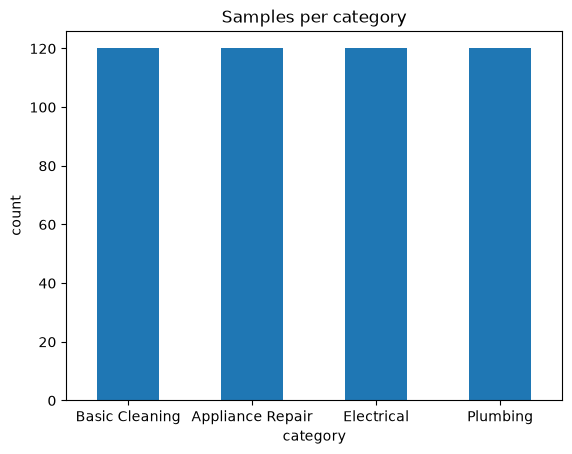

count    480.000000
mean       8.400000
std        2.171749
min        4.000000
25%        7.000000
50%        8.000000
75%       10.000000
max       15.000000
Name: text, dtype: float64

In [3]:
print(df["category"].value_counts())
df["category"].value_counts().plot(kind="bar", title="Samples per category", rot=0)
plt.ylabel("count"); plt.show()
df["text"].str.split().str.len().describe()

## 3. Preprocessing
- Lowercasing is done inside `TfidfVectorizer`.
- **Character n-grams (2-5)** with `char_wb` make the model robust to typos and to inconsistent Romanized Nepali spelling (e.g. *bijuli / bijli*).
- `sublinear_tf=True` dampens the effect of repeated characters.

**Important:** to avoid data leakage, train/test splits are done **by group**, so the same problem phrase never appears in both train and test.

In [4]:
def tfidf():
    return TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

## 4. Compare algorithms (5-fold grouped cross-validation)

In [5]:
models = {
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10),
    "Linear SVM": LinearSVC(C=1),
}
cv = GroupKFold(n_splits=5)
results = []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    acc = cross_val_score(pipe, df["text"], df["category"], groups=df["group"], cv=cv, scoring="accuracy")
    f1 = cross_val_score(pipe, df["text"], df["category"], groups=df["group"], cv=cv, scoring="f1_macro")
    results.append({"model": name, "accuracy": acc.mean(), "macro_f1": f1.mean(), "f1_std": f1.std()})
results_df = pd.DataFrame(results).round(3)
results_df

,model,accuracy,macro_f1,f1_std
0,Naive Bayes,0.788,0.785,0.083
1,Logistic Regression,0.835,0.836,0.098
2,Linear SVM,0.844,0.842,0.109


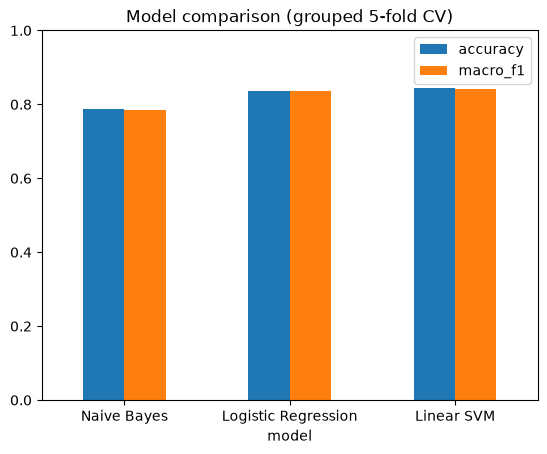

In [6]:
results_df.set_index("model")[["accuracy", "macro_f1"]].plot(kind="bar", rot=0, ylim=(0, 1), title="Model comparison (grouped 5-fold CV)")
plt.show()

## 5. Hold-out evaluation of the chosen model
**Logistic Regression** is used in the app: its accuracy is close to the SVM, and it gives class probabilities, which the API needs for confidence scores.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, df["category"], groups=df["group"]))
X_train, y_train = df.iloc[train_idx]["text"], df.iloc[train_idx]["category"]
X_test,  y_test  = df.iloc[test_idx]["text"],  df.iloc[test_idx]["category"]

model = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=2000, C=10))])
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Macro F1 :", round(f1_score(y_test, pred, average="macro"), 3))
print(classification_report(y_test, pred))

Accuracy : 0.812
Macro F1 : 0.814
                  precision    recall  f1-score   support

Appliance Repair       0.95      0.63      0.76        30
  Basic Cleaning       0.72      1.00      0.84        18
      Electrical       1.00      0.78      0.88        27
        Plumbing       0.67      0.95      0.78        21

        accuracy                           0.81        96
       macro avg       0.83      0.84      0.81        96
    weighted avg       0.86      0.81      0.81        96



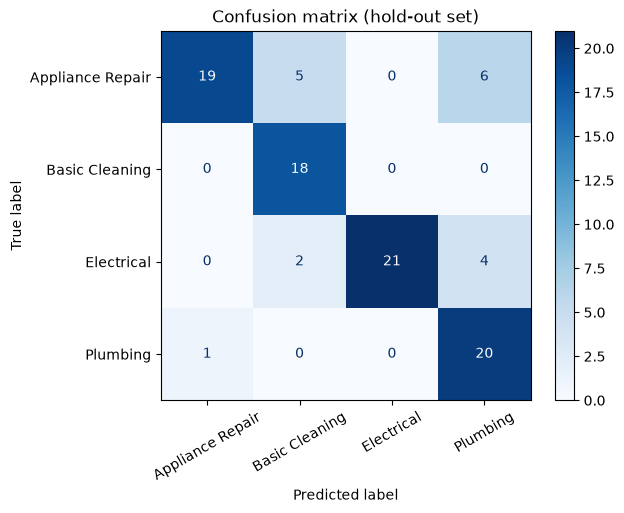

In [8]:
cm = confusion_matrix(y_test, pred, labels=model.classes_)
ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot(cmap="Blues", xticks_rotation=30)
plt.title("Confusion matrix (hold-out set)"); plt.show()

## 6. Error analysis

In [9]:
errors = pd.DataFrame({"text": X_test.values, "actual": y_test.values, "predicted": pred})
errors[errors["actual"] != errors["predicted"]].head(15)

,text,actual,predicted
4,can someone come today? washing area tap is br...,Plumbing,Appliance Repair
6,"hello, ghar ma naya batti lagaunu paryo",Electrical,Basic Cleaning
14,computer is very slow and shuts down this weekend,Appliance Repair,Basic Cleaning
15,"looking for a provider, no power supply in the...",Electrical,Plumbing
19,"hello, kitchen ko cabinet repair garnu paryo n...",Appliance Repair,Basic Cleaning
26,no power supply in the kitchen as soon as poss...,Electrical,Plumbing
45,urgent: ac ma pani chuhiyeko cha in bhaktapur,Appliance Repair,Plumbing
56,"looking for a providr, ghar ma naya batti laga...",Electrical,Basic Cleaning
57,"hello, computer is very slow and shuts down",Appliance Repair,Basic Cleaning
58,"looking for a provider, ac ma pani chuhiyeko c...",Appliance Repair,Plumbing


## 7. Train the final model on all data and save it for Django

In [10]:
final = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=2000, C=10))])
final.fit(df["text"], df["category"])
joblib.dump(final, "ml/model.joblib")
print("Saved backend/ml/model.joblib")

Saved backend/ml/model.joblib


## 8. Try it on new sentences

In [11]:
samples = ["my kitchen sink is leaking badly", "bijuli gayo", "washing machine is making noise",
           "need someone to clean my flat", "ac not cooling", "tap bata pani chuhiyo"]
for s in samples:
    probs = final.predict_proba([s])[0]
    top = np.argsort(probs)[::-1][:2]
    print(f"{s!r:45} -> " + ", ".join(f"{final.classes_[i]} ({probs[i]:.0%})" for i in top))

'my kitchen sink is leaking badly'            -> Plumbing (92%), Electrical (3%)
'bijuli gayo'                                 -> Electrical (95%), Plumbing (2%)
'washing machine is making noise'             -> Appliance Repair (90%), Plumbing (5%)
'need someone to clean my flat'               -> Basic Cleaning (90%), Appliance Repair (4%)
'ac not cooling'                              -> Appliance Repair (97%), Electrical (2%)
'tap bata pani chuhiyo'                       -> Plumbing (99%), Appliance Repair (1%)


## 9. Limitations
- The dataset is **synthetic and small** (written by the developer from template phrases), not real customer messages, so real-world accuracy will be lower than these numbers.
- Some problems are genuinely ambiguous (e.g. *geyser*, *fan*, *water tank* can be Plumbing, Electrical, Repair or Cleaning).
- Only four categories, with limited Romanized Nepali coverage.
- Future work: collect real booking descriptions from FixNepal, add more categories, and retrain.